## 1. Fonte dos dados e contexto

Neste projeto, realizo uma análise exploratória da base **Pima Indians Diabetes Database**, disponibilizada no Kaggle.

O objetivo é investigar a distribuição das variáveis, comparar características dos registros classificados com e sem diabetes e identificar possíveis problemas de qualidade dos dados.
A base contém 768 registros e 9 variáveis, incluindo características demográficas, medidas clínicas e a variável `diabetes` que identifica as duas categorias analisadas na base: 0 e 1.


**Fonte:** [Pima Indians Diabetes Database — Kaggle](https://www.kaggle.com/datasets/kumargh/pimaindiansdiabetescsv)

**Origem do arquivo utilizado:** o arquivo CSV é carregado diretamente de um repositório público no GitHub, por meio de uma URL utilizada no código deste notebook.

**Origem informada:** National Institute of Diabetes and Digestive and Kidney Diseases (NIDDK).

**População representada:** mulheres da população Pima, com 21 anos ou mais.

### Descrição das variáveis

| Variável | Descrição |
|---|---|
| `pregnancies` | Número de gestações |
| `glucose` | Concentração plasmática de glicose medida duas horas após um teste oral de tolerância à glicose |
| `diastolic` | Pressão arterial diastólica, em mmHg |
| `triceps` | Espessura da dobra cutânea do tríceps, em milímetros |
| `insulin` | Concentração de insulina sérica medida duas horas após o teste, em µU/mL |
| `bmi` | Índice de massa corporal (IMC), calculado pelo peso dividido pela altura ao quadrado |
| `dpf` | Diabetes Pedigree Function, indicador relacionado ao histórico familiar de diabetes |
| `age` | Idade em anos |
| `diabetes` | Categoria binária: `0` para resultado negativo e `1` para resultado positivo para diabetes |

In [34]:
import pandas as pd

url = "https://raw.githubusercontent.com/ApnaClassroom/Dataset/a6bcba4b6f9b87d8f924df1dacad300785571cfe/Diabetes.csv"

df = pd.read_csv(url)

## 2. Exploração inicial dos dados

Nesta etapa, examinarei a estrutura da base para identificar sua dimensão, as variáveis disponíveis, os tipos de dados e a presença de valores ausentes. Também analisarei as estatísticas descritivas para compreender as escalas e a distribuição inicial das variáveis.

In [35]:
df.shape

(768, 9)

In [36]:
df.columns

Index(['pregnancies', 'glucose', 'diastolic', 'triceps', 'insulin', 'bmi',
       'dpf', 'age', 'diabetes'],
      dtype='object')

In [37]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   pregnancies  768 non-null    int64  
 1   glucose      768 non-null    int64  
 2   diastolic    768 non-null    int64  
 3   triceps      768 non-null    int64  
 4   insulin      768 non-null    int64  
 5   bmi          768 non-null    float64
 6   dpf          768 non-null    float64
 7   age          768 non-null    int64  
 8   diabetes     768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [38]:
df.isnull().sum()

,0
pregnancies,0
glucose,0
diastolic,0
triceps,0
insulin,0
bmi,0
dpf,0
age,0
diabetes,0


In [39]:
df.describe()

,pregnancies,glucose,diastolic,triceps,insulin,bmi,dpf,age,diabetes
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


## 3. Análise exploratória das variáveis

### Distribuição da categoria de diabetes

In [40]:
distribuicao_diabetes = pd.DataFrame({
    "Quantidade": df["diabetes"].value_counts().sort_index(),
    "Percentual (%)": (
        df["diabetes"]
        .value_counts(normalize=True)
        .sort_index()
        .mul(100)
        .round(2)
    )
})

distribuicao_diabetes

,Quantidade,Percentual (%)
diabetes,,
0,500,65.1
1,268,34.9


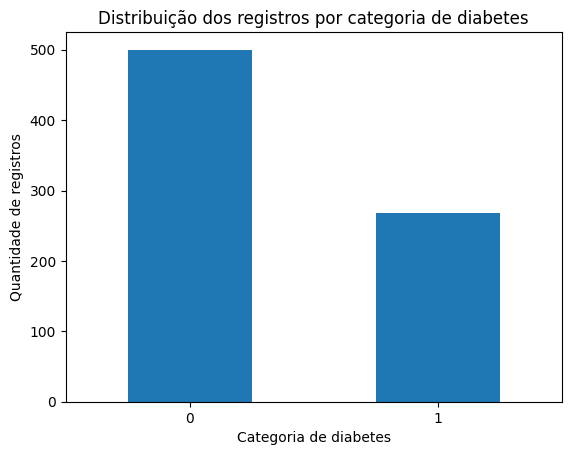

In [41]:
import matplotlib.pyplot as plt

df["diabetes"].value_counts().sort_index().plot(kind="bar")

plt.title("Distribuição dos registros por categoria de diabetes")
plt.xlabel("Categoria de diabetes")
plt.ylabel("Quantidade de registros")
plt.xticks(rotation=0)
plt.show()

A base apresenta maior proporção de registros classificados na categoria 0, que representa 65,1% do total. A categoria 1 corresponde a 34,9% dos registros. Essa diferença caracteriza uma distribuição desigual entre as categorias.

### Distribuição da glicose

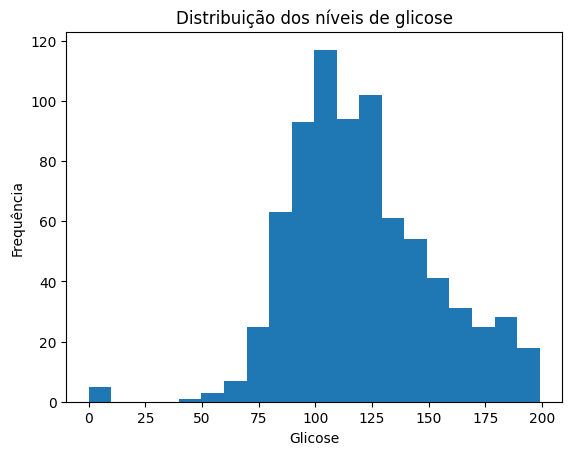

In [42]:
plt.hist(df["glucose"], bins=20)

plt.title("Distribuição dos níveis de glicose")
plt.xlabel("Glicose")
plt.ylabel("Frequência")
plt.show()

O histograma mostra maior concentração de registros em níveis intermediários de glicose, especialmente na faixa aproximada de 90 a 130. A distribuição apresenta uma cauda em direção aos valores mais elevados, sugerindo assimetria à direita.


### Distribuição das idades

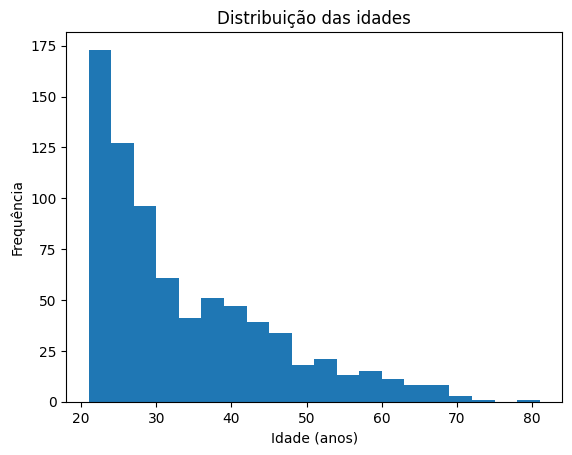

In [43]:
plt.hist(df["age"], bins=20)

plt.title("Distribuição das idades")
plt.xlabel("Idade (anos)")
plt.ylabel("Frequência")

plt.show()

A distribuição apresenta maior concentração de registros nas idades mais baixas, com redução da frequência conforme a idade aumenta.

### Distribuição da idade por categoria de diabetes

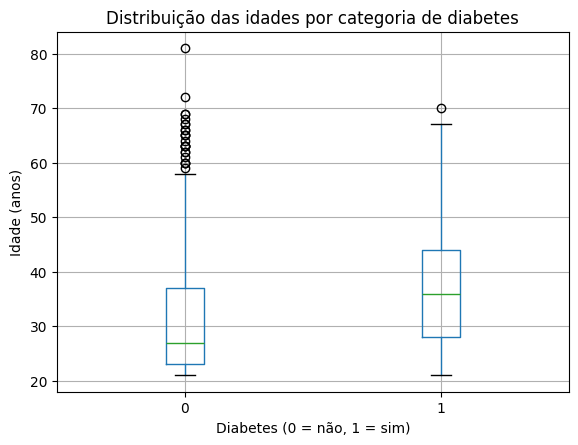

In [44]:
df.boxplot(column="age", by="diabetes")

plt.title("Distribuição das idades por categoria de diabetes")
plt.suptitle("")
plt.xlabel("Diabetes (0 = não, 1 = sim)")
plt.ylabel("Idade (anos)")

plt.show()

A comparação dos boxplots indica que o grupo com diabetes apresenta mediana de idade superior à do grupo sem diabetes. A distribuição das idades do grupo com diabetes também está posicionada em faixas etárias mais elevadas.

Foram identificados possíveis valores atípicos, principalmente no grupo sem diabetes. Esses registros não devem ser considerados erros automaticamente, pois podem representar observações legítimas.

Os resultados sugerem uma associação entre idade e a categoria de diabetes nesta base de dados, mas não permitem estabelecer uma relação causal.

### Distribuição da glicose por categoria de diabetes

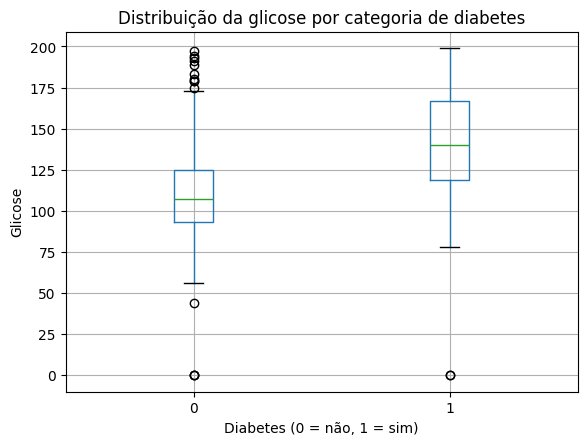

In [45]:
df.boxplot(column="glucose", by="diabetes")

plt.title("Distribuição da glicose por categoria de diabetes")
plt.suptitle("")
plt.xlabel("Diabetes (0 = não, 1 = sim)")
plt.ylabel("Glicose")

plt.show()

A comparação dos boxplots mostra que o grupo classificado com diabetes apresenta uma mediana de glicose mais elevada do que o grupo sem diabetes. Os 50% centrais dos valores também se concentram em níveis mais altos nesse grupo.
Os resultados sugerem uma associação entre os níveis de glicose e a categoria de diabetes nesta base.

## 4. Qualidade dos dados


### Investigação de valores zero

In [46]:
colunas_clinicas = [
    "glucose",
    "diastolic",
    "triceps",
    "insulin",
    "bmi"
]

In [47]:
resumo_zeros = pd.DataFrame({
    "Quantidade": (df[colunas_clinicas] == 0).sum(),
    "Percentual (%)": (
        (df[colunas_clinicas] == 0)
        .mean()
        .mul(100)
        .round(2)
    )
})

resumo_zeros

,Quantidade,Percentual (%)
glucose,5,0.65
diastolic,35,4.56
triceps,227,29.56
insulin,374,48.70
bmi,11,1.43


In [48]:
registros_com_zero = (df[colunas_clinicas] == 0).any(axis=1).sum()

print(f"Registros com pelo menos um zero: {registros_com_zero}")
print(f"Percentual: {registros_com_zero / len(df) * 100:.2f}%")

Registros com pelo menos um zero: 376
Percentual: 48.96%


In [49]:
registros_com_multiplos_zeros = (
    (df[colunas_clinicas] == 0).sum(axis=1) >= 2
).sum()

print(
    f"Registros com zeros em duas ou mais variáveis: "
    f"{registros_com_multiplos_zeros}"
)

print(
    f"Percentual: "
    f"{registros_com_multiplos_zeros / len(df) * 100:.2f}%"
)

Registros com zeros em duas ou mais variáveis: 234
Percentual: 30.47%


In [50]:
import numpy as np

df_tratado = df.copy()

colunas_com_zeros_invalidos = [
    "glucose",
    "diastolic",
    "triceps",
    "insulin",
    "bmi"
]

for coluna in colunas_com_zeros_invalidos:
    df_tratado[coluna] = df_tratado[coluna].replace(0, np.nan)

In [51]:
df_tratado.isnull().sum()

,0
pregnancies,0
glucose,5
diastolic,35
triceps,227
insulin,374
bmi,11
dpf,0
age,0
diabetes,0


In [52]:
df_tratado.shape

(768, 9)

Ao investigar a qualidade dos dados, identifiquei valores iguais a zero nas variáveis clínicas `glucose`, `diastolic`, `triceps`, `insulin` e `bmi`. A verificação inicial não identificou valores nulos explícitos, mas algumas variáveis apresentaram uma quantidade significativa de zeros.

Identifiquei que 376 registros (48,96% da base) apresentavam pelo menos um zero nessas variáveis, enquanto 234 registros (30,47%) apresentavam zeros em duas ou mais delas. As maiores quantidades de zeros foram observadas em `insulin` e `triceps`.

Para investigar o possível impacto desses valores, preservei o DataFrame original (`df`) e criei uma cópia de trabalho (`df_tratado`). Nessa cópia, substituí por valores ausentes os zeros encontrados nas cinco variáveis clínicas selecionadas. Dessa forma, foi possível comparar os resultados antes e depois do tratamento sem alterar a base original.



## 5. Análise de correlação

In [53]:
correlacao = df_tratado.corr(numeric_only=True)

correlacao.round(2)

,pregnancies,glucose,diastolic,triceps,insulin,bmi,dpf,age,diabetes
pregnancies,1.00,0.13,0.21,0.10,0.08,0.02,-0.03,0.54,0.22
glucose,0.13,1.00,0.22,0.23,0.58,0.23,0.14,0.27,0.49
diastolic,0.21,0.22,1.00,0.23,0.10,0.29,-0.00,0.33,0.17
triceps,0.10,0.23,0.23,1.00,0.18,0.65,0.12,0.17,0.26
insulin,0.08,0.58,0.10,0.18,1.00,0.23,0.13,0.22,0.30
bmi,0.02,0.23,0.29,0.65,0.23,1.00,0.16,0.03,0.31
dpf,-0.03,0.14,-0.00,0.12,0.13,0.16,1.00,0.03,0.17
age,0.54,0.27,0.33,0.17,0.22,0.03,0.03,1.00,0.24
diabetes,0.22,0.49,0.17,0.26,0.30,0.31,0.17,0.24,1.00


Calculei a matriz de correlação entre as variáveis numéricas para investigar possíveis associações lineares após o tratamento dos valores zero.

A variável `glucose` apresentou a maior correlação positiva com `diabetes` (0,495), seguida por `bmi` (0,314), `insulin` (0,303), `triceps` (0,259), `age` (0,238) e `pregnancies` (0,222).

Também identifiquei uma correlação de 0,54 entre `pregnancies` e `age`, além de uma correlação de aproximadamente 0,18 entre `triceps` e `insulin`.

Esses resultados são exploratórios. A correlação mede associações lineares e não demonstra causalidade. Além disso, as proporções de valores ausentes em algumas variáveis, especialmente `insulin` e `triceps`, devem ser consideradas na interpretação.


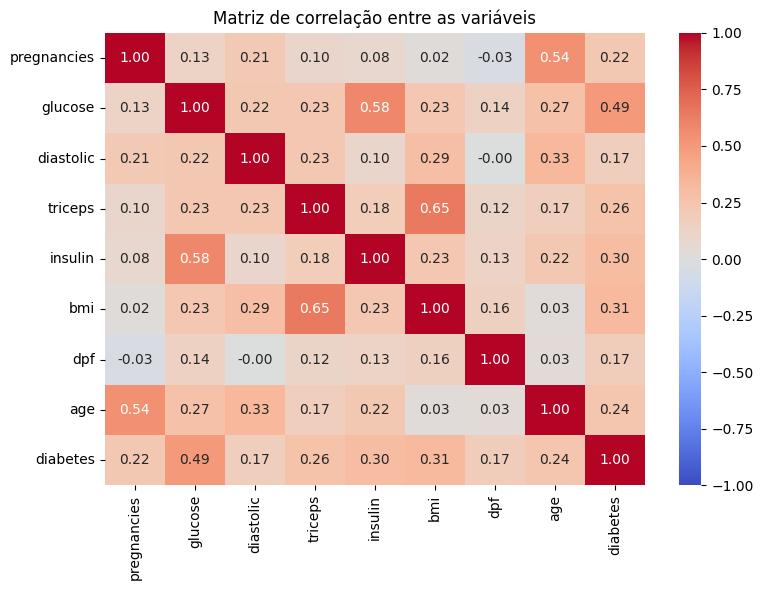

In [54]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlacao,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Matriz de correlação entre as variáveis")
plt.tight_layout()
plt.show()

O mapa de calor facilita a comparação visual entre os coeficientes de correlação, destacando a associação positiva entre glicose e a categoria de diabetes, além das associações observadas entre as demais variáveis.

In [55]:
# Correlações antes do tratamento
correlacao_original = df.corr(numeric_only=True)

# Correlações depois do tratamento
correlacao_tratada = df_tratado.corr(numeric_only=True)

# Comparar as correlações com a variável diabetes
comparacao_correlacoes = pd.DataFrame({
    "Original": correlacao_original["diabetes"],
    "Após tratamento": correlacao_tratada["diabetes"]
})

comparacao_correlacoes["Diferença"] = (
    comparacao_correlacoes["Após tratamento"]
    - comparacao_correlacoes["Original"]
)

comparacao_correlacoes.round(3)

,Original,Após tratamento,Diferença
pregnancies,0.222,0.222,0.000
glucose,0.467,0.495,0.028
diastolic,0.065,0.171,0.106
triceps,0.075,0.259,0.185
insulin,0.131,0.303,0.173
bmi,0.293,0.314,0.021
dpf,0.174,0.174,0.000
age,0.238,0.238,0.000
diabetes,1.000,1.000,0.000


Após substituir os zeros das variáveis clínicas selecionadas por valores ausentes, observei mudanças nas correlações com a categoria de diabetes. As alterações mais expressivas ocorreram nas variáveis `triceps`, cuja correlação passou de 0,075 para 0,259, e `insulin`, que passou de 0,131 para 0,303. A correlação de `diastolic` também aumentou, de 0,065 para 0,171.

A correlação entre glicose e diabetes permaneceu como a mais elevada, passando de 0,467 para 0,495. Em contrapartida, as correlações de `pregnancies`, `dpf` e `age` permaneceram inalteradas.

Esses resultados demonstram que o tratamento dos valores zero pode influenciar a interpretação das associações entre as variáveis.

In [56]:
resumo_dados_tratados = pd.DataFrame({
    "Valores disponíveis": df_tratado.count(),
    "Valores ausentes": df_tratado.isnull().sum(),
    "Percentual ausente": df_tratado.isnull().mean() * 100
})

resumo_dados_tratados.round(2)

,Valores disponíveis,Valores ausentes,Percentual ausente
pregnancies,768,0,0.00
glucose,763,5,0.65
diastolic,733,35,4.56
triceps,541,227,29.56
insulin,394,374,48.70
bmi,757,11,1.43
dpf,768,0,0.00
age,768,0,0.00
diabetes,768,0,0.00


Após tratar os zeros das cinco variáveis clínicas selecionadas como valores ausentes, observei diferenças importantes na disponibilidade dos dados. As variáveis `glucose`, `diastolic` e `bmi` apresentam menos de 5% de valores ausentes, enquanto `triceps` possui 29,56% e `insulin`, 48,70%.

A quantidade de valores ausentes em `insulin` e `triceps` exige atenção, pois reduz o número de observações disponíveis para as análises que envolvem essas variáveis. Optei por preservar os registros e não realizar imputações nesta etapa, considerando o caráter exploratório do projeto.


## 6. Conclusão

Nesta análise exploratória, investiguei a distribuição das variáveis clínicas, comparei os grupos com e sem diabetes e avaliei a qualidade dos dados. As análises mostraram diferenças na distribuição das idades e dos níveis de glicose entre os grupos.

Na matriz de correlação após o tratamento dos valores zero, a glicose apresentou a maior correlação positiva com a categoria de diabetes (0,495), seguida pelo IMC (0,314) e pela insulina (0,303). Também observei alterações nas correlações de algumas variáveis após o tratamento, principalmente `triceps`, `insulin` e `diastolic`, indicando que a forma como os valores zero são tratados pode influenciar os resultados.

A investigação identificou valores zero em cinco variáveis clínicas. Esses valores foram substituídos por valores ausentes em uma cópia da base, preservando os dados originais. Entretanto, essa decisão foi baseada na possibilidade de que representassem medições ausentes ou inválidas, sem confirmação individual de todos os casos. A proporção de valores ausentes em `insulin` e `triceps` também limita as análises que envolvem essas variáveis.

Os resultados permitem identificar padrões e associações nos dados, mas devem ser interpretados considerando essas limitações. As correlações observadas não demonstram causalidade, e a análise não tem como objetivo estabelecer diagnósticos ou conclusões clínicas.

